# EV Charging Demand Forecasting

## Step 1 — Load Cleaned Dataset

In [23]:
import pandas as pd

# Load cleaned dataset
df = pd.read_csv("Data_row/cleaned data/ChargingRecords_Cleaned.csv")

# Convert date column
df["StartDatetime"] = pd.to_datetime(df["StartDatetime"])

print("Dataset loaded successfully!")

Dataset loaded successfully!


## Step 2 — Create Daily Charging Demand

In [25]:

# Calculate total demand for each day
daily_demand = (
    df.groupby(df["StartDatetime"].dt.date)["Demand"]
    .sum()
    .reset_index()
)

# Rename columns
daily_demand.columns = ["Date", "TotalDemand"]

# Convert Date into datetime
daily_demand["Date"] = pd.to_datetime(daily_demand["Date"])

# Display results
print("Total Days:", len(daily_demand))
print("Date Range:", daily_demand["Date"].min(), "to", daily_demand["Date"].max())

daily_demand.head(10)


Total Days: 366
Date Range: 2021-09-30 00:00:00 to 2022-09-30 00:00:00


,Date,TotalDemand
0,2021-09-30,579.19
1,2021-10-01,2467.59
2,2021-10-02,2087.75
3,2021-10-03,1928.25
4,2021-10-04,1768.66
5,2021-10-05,2530.86
6,2021-10-06,2300.17
7,2021-10-07,2113.15
8,2021-10-08,2266.41
9,2021-10-09,1688.26


## Step 3 — Prepare Daily Time Series

In [26]:
# Remove incomplete first day
daily_demand = daily_demand[
    daily_demand["Date"] >= "2021-10-01"
].copy()

# Set Date as index
daily_demand = daily_demand.set_index("Date")

# Sort by date
daily_demand = daily_demand.sort_index()

# Check missing dates
print("Total Days:", len(daily_demand))
print("Missing Dates:", len(
    pd.date_range(
        daily_demand.index.min(),
        daily_demand.index.max()
    ).difference(daily_demand.index)
))

# Display first 5 days
daily_demand.head()

Total Days: 365
Missing Dates: 0


,TotalDemand
Date,
2021-10-01,2467.59
2021-10-02,2087.75
2021-10-03,1928.25
2021-10-04,1768.66
2021-10-05,2530.86


## Step 4 — Visualize Daily Charging Demand

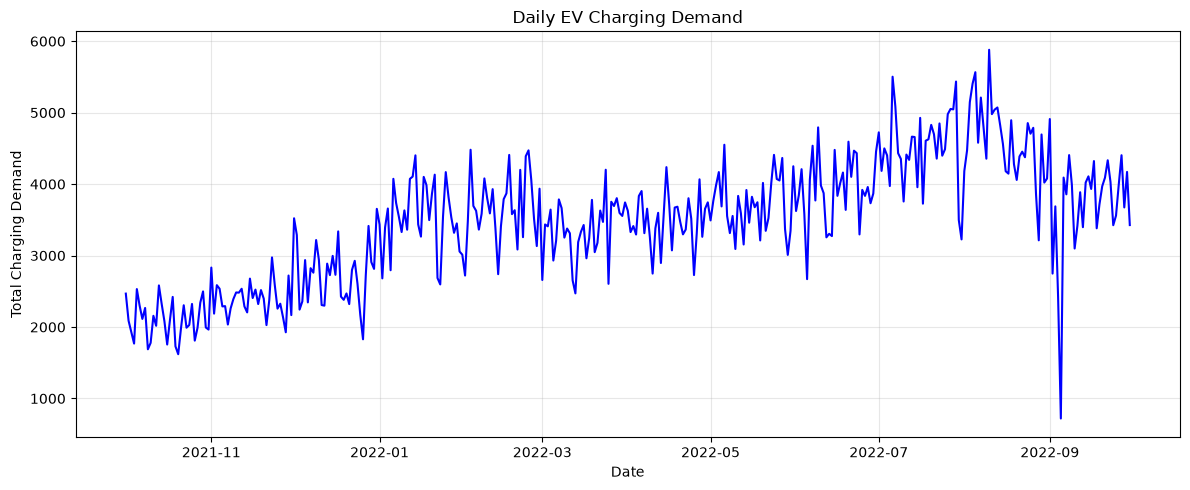

In [27]:
import matplotlib.pyplot as plt

# Create daily demand chart
plt.figure(figsize=(12, 5))

plt.plot(
    daily_demand.index,
    daily_demand["TotalDemand"],
    color="blue"
)

plt.title("Daily EV Charging Demand")
plt.xlabel("Date")
plt.ylabel("Total Charging Demand")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Step 5 — Create Moving Averages

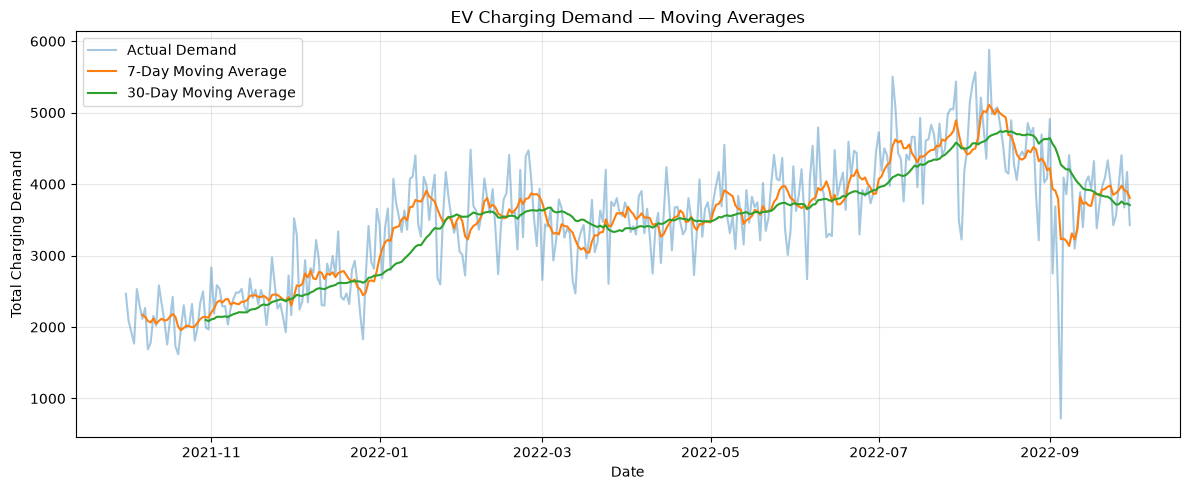

In [28]:
# Calculate moving averages
daily_demand["MA_7"] = daily_demand["TotalDemand"].rolling(window=7).mean()
daily_demand["MA_30"] = daily_demand["TotalDemand"].rolling(window=30).mean()

# Plot actual demand and moving averages
plt.figure(figsize=(12, 5))

plt.plot(
    daily_demand.index,
    daily_demand["TotalDemand"],
    label="Actual Demand",
    alpha=0.4
)

plt.plot(
    daily_demand.index,
    daily_demand["MA_7"],
    label="7-Day Moving Average"
)

plt.plot(
    daily_demand.index,
    daily_demand["MA_30"],
    label="30-Day Moving Average"
)

plt.title("EV Charging Demand — Moving Averages")
plt.xlabel("Date")
plt.ylabel("Total Charging Demand")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 6 — Split Time Series Data


In [29]:
# Select daily demand values
series = daily_demand["TotalDemand"]

# Calculate 80% split
split_index = int(len(series) * 0.8)

# Split data chronologically
train = series.iloc[:split_index]
test = series.iloc[split_index:]

# Display results
print("Training Days:", len(train))
print("Testing Days:", len(test))

print("Training Period:", train.index.min(), "to", train.index.max())
print("Testing Period:", test.index.min(), "to", test.index.max())

Training Days: 292
Testing Days: 73
Training Period: 2021-10-01 00:00:00 to 2022-07-19 00:00:00
Testing Period: 2022-07-20 00:00:00 to 2022-09-30 00:00:00


## Step 7 — Moving Average Forecasting

In [30]:
# Calculate average demand from last 7 training days
last_7_days = train.tail(7)

moving_average_forecast = last_7_days.mean()

# Predict all 73 testing days
ma_predictions = pd.Series(
    moving_average_forecast,
    index=test.index
)

# Display results
print("7-Day Moving Average:", round(moving_average_forecast, 2))
print("Forecast Days:", len(ma_predictions))

ma_predictions.head(10)

7-Day Moving Average: 4452.33
Forecast Days: 73


Date
2022-07-20    4452.334286
2022-07-21    4452.334286
2022-07-22    4452.334286
2022-07-23    4452.334286
2022-07-24    4452.334286
2022-07-25    4452.334286
2022-07-26    4452.334286
2022-07-27    4452.334286
2022-07-28    4452.334286
2022-07-29    4452.334286
dtype: float64

## Step 8 — Evaluate Moving Average Forecast

In [31]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate forecasting errors
ma_mae = mean_absolute_error(test, ma_predictions)
ma_mse = mean_squared_error(test, ma_predictions)
ma_rmse = np.sqrt(ma_mse)

# Display results
print("Moving Average Forecast Performance")
print("-----------------------------------")
print("MAE :", round(ma_mae, 2))
print("RMSE:", round(ma_rmse, 2))

Moving Average Forecast Performance
-----------------------------------
MAE : 588.84
RMSE: 810.42


## Step 9 — Exponential Smoothing Forecasting

In [32]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Create Exponential Smoothing model
es_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal=None,
    initialization_method="estimated"
)

# Train model
es_fit = es_model.fit(optimized=True)

# Forecast next 73 days
es_predictions = es_fit.forecast(len(test))

# Display predictions
print("Forecast Days:", len(es_predictions))

es_predictions.head(10).round(2)

Forecast Days: 73


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


2022-07-20    4470.02
2022-07-21    4477.76
2022-07-22    4485.49
2022-07-23    4493.23
2022-07-24    4500.96
2022-07-25    4508.70
2022-07-26    4516.43
2022-07-27    4524.17
2022-07-28    4531.90
2022-07-29    4539.64
Freq: D, dtype: float64

## Step 10 — Compare Forecasting Models

In [33]:
# Calculate Exponential Smoothing errors
es_mae = mean_absolute_error(test, es_predictions)
es_mse = mean_squared_error(test, es_predictions)
es_rmse = np.sqrt(es_mse)

# Compare both models
forecast_results = pd.DataFrame({
    "Model": [
        "Moving Average (7-Day)",
        "Exponential Smoothing"
    ],
    "MAE": [ma_mae, es_mae],
    "RMSE": [ma_rmse, es_rmse]
})

# Sort by lowest RMSE
forecast_results = forecast_results.sort_values(
    "RMSE"
).reset_index(drop=True)

forecast_results.round(2)

,Model,MAE,RMSE
0,Moving Average (7-Day),588.84,810.42
1,Exponential Smoothing,773.73,1014.07


## Step 11 — Actual vs Forecasted Demand

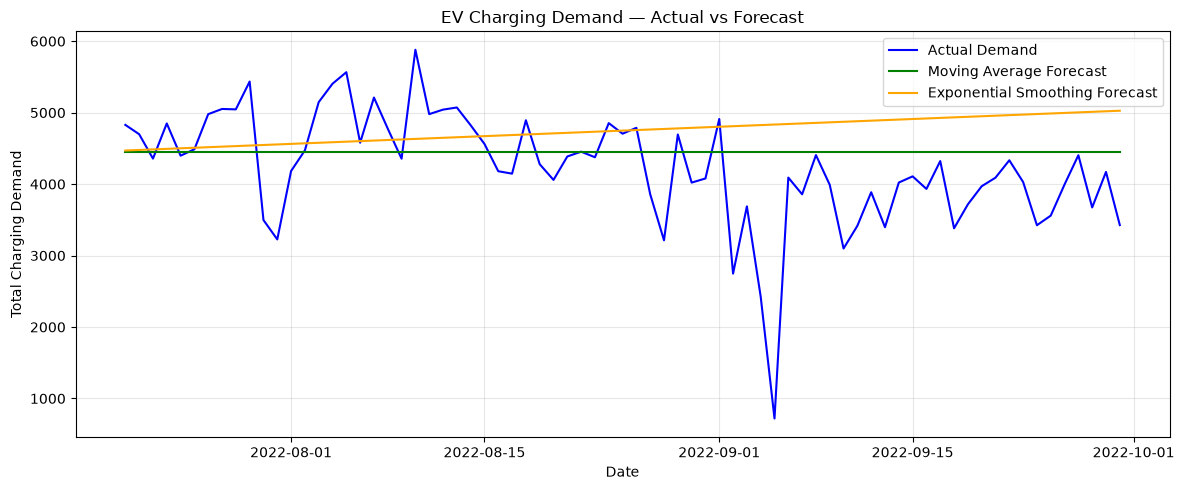

In [34]:
import matplotlib.pyplot as plt

# Create comparison chart
plt.figure(figsize=(12, 5))

# Actual demand
plt.plot(
    test.index,
    test,
    label="Actual Demand",
    color="blue"
)

# Moving Average predictions
plt.plot(
    test.index,
    ma_predictions,
    label="Moving Average Forecast",
    color="green"
)

# Exponential Smoothing predictions
plt.plot(
    test.index,
    es_predictions,
    label="Exponential Smoothing Forecast",
    color="orange"
)

plt.title("EV Charging Demand — Actual vs Forecast")
plt.xlabel("Date")
plt.ylabel("Total Charging Demand")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Step 12 — Check Weekly Demand Patterns

In [35]:
# Calculate average demand for each weekday
weekly_demand = daily_demand.copy()

weekly_demand["DayOfWeek"] = weekly_demand.index.day_name()

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekly_average = (
    weekly_demand.groupby("DayOfWeek")["TotalDemand"]
    .mean()
    .reindex(weekday_order)
)

# Display results
print("Average Daily Charging Demand by Weekday")
print(weekly_average.round(2))

Average Daily Charging Demand by Weekday
DayOfWeek
Monday       3444.56
Tuesday      3501.26
Wednesday    3667.13
Thursday     3736.42
Friday       3595.25
Saturday     3330.94
Sunday       3078.31
Name: TotalDemand, dtype: float64


## Step 13 — Weekly Seasonal Forecasting3.

In [36]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Create model with weekly seasonality
seasonal_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
)

# Train model
seasonal_fit = seasonal_model.fit(optimized=True)

# Forecast testing period
seasonal_predictions = seasonal_fit.forecast(len(test))

# Calculate errors
seasonal_mae = mean_absolute_error(test, seasonal_predictions)
seasonal_rmse = np.sqrt(mean_squared_error(test, seasonal_predictions))

# Display results
print("Weekly Seasonal Forecast Performance")
print("------------------------------------")
print("MAE :", round(seasonal_mae, 2))
print("RMSE:", round(seasonal_rmse, 2))

Weekly Seasonal Forecast Performance
------------------------------------
MAE : 784.61
RMSE: 1018.28


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


## Step 14 — Compare All Forecasting Models

In [46]:
# Compare all forecasting models
final_forecast_results = pd.DataFrame({
    "Model": [
        "Moving Average (7-Day)",
        "Exponential Smoothing",
        "Weekly Seasonal Forecasting"
    ],
    "MAE": [
        ma_mae,
        es_mae,
        seasonal_mae
    ],
    "RMSE": [
        ma_rmse,
        es_rmse,
        seasonal_rmse
    ]
})

# Sort models by lowest RMSE
final_forecast_results = final_forecast_results.sort_values(
    "RMSE"
).reset_index(drop=True)

# Display comparison
final_forecast_results.round(2)

,Model,MAE,RMSE
0,Moving Average (7-Day),588.84,810.42
1,Exponential Smoothing,773.73,1014.07
2,Weekly Seasonal Forecasting,784.61,1018.28


In [45]:
# Step 14A — Seasonal Naïve Forecasting

# Get the last 7 days of training demand
last_week = train.tail(7).to_numpy()

# Repeat the weekly pattern for the test period
seasonal_naive_predictions = pd.Series(
    [last_week[i % 7] for i in range(len(test))],
    index=test.index
)

# Calculate forecasting errors
seasonal_naive_mae = mean_absolute_error(
    test, seasonal_naive_predictions
)

seasonal_naive_rmse = mean_squared_error(
    test, seasonal_naive_predictions
) ** 0.5

print("MAE:", round(seasonal_naive_mae, 2))
print("RMSE:", round(seasonal_naive_rmse, 2))

MAE: 627.32
RMSE: 857.96


## Step 15 — Generate Future Charging Demand Forecast

In [39]:
# Step 15 — Future Charging Demand Forecast

from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Prepare daily demand
full_series = daily_demand["TotalDemand"].asfreq("D")

# Train forecasting model
model = ExponentialSmoothing(
    full_series,
    trend="add",
    seasonal="add",
    seasonal_periods=7
)

model_fit = model.fit()

# Forecast next 30 days
predictions = model_fit.forecast(30)

# Create forecast table
future_forecast = pd.DataFrame({
    "Date": predictions.index,
    "PredictedDemand": predictions.values
})

future_forecast.head(10)

,Date,PredictedDemand
0,2022-10-01,3660.177199
1,2022-10-02,3408.299176
2,2022-10-03,3774.336502
3,2022-10-04,3831.230015
4,2022-10-05,3997.074517
5,2022-10-06,4066.338860
6,2022-10-07,3948.806451
7,2022-10-08,3691.631652
8,2022-10-09,3439.753629
9,2022-10-10,3805.790955


## Step 16 — Save Future Demand Forecast

In [41]:
import os

# Create folder for forecasting results
os.makedirs("forecasts", exist_ok=True)

# Save future predictions
future_forecast.to_csv(
    "forecasts/future_charging_demand.csv",
    index=False
)

# Save model comparison
final_forecast_results.to_csv(
    "forecasts/forecast_model_comparison.csv",
    index=False
)

print("Future forecast saved successfully!")
print("Model comparison saved successfully!")

Future forecast saved successfully!
Model comparison saved successfully!


## Step 17 — Validate Saved Forecast.

In [42]:
import pandas as pd

future_forecast = pd.read_csv(
    "forecasts/future_charging_demand.csv"
)

print("Total days:", len(future_forecast))
print("Unique predictions:", future_forecast["PredictedDemand"].nunique())

Total days: 30
Unique predictions: 30
